# Oscillatory signals

In [1]:
import matplotlib.pyplot as plt
import mne
from moabb.datasets import Rodrigues2017
import numpy as np
import os
import scipy.fft as fft 
from scipy.signal import spectrogram, chirp, hilbert, butter, sosfilt, detrend
import warnings

np.random.seed(42)
warnings.simplefilter(action='ignore', category=RuntimeWarning)
mne.set_log_level('WARNING')

## Exercise 1: Load the data

The following uses [MOABB](https://moabb.neurotechx.com/docs/index.html) to download the [Rodrigues2017 dataset](https://moabb.neurotechx.com/docs/generated/moabb.datasets.Rodrigues2017.html#moabb.datasets.Rodrigues2017) from [Rodrigues et al. 2017](https://hal.science/hal-02086581). The dataset contains eyes-open and eyes-closed trials. 
1. Read the dataset documentation to get to know the data properties and the task underlying the data.

SHA256 hash of downloaded file: f178eac0720679bac17e4cc18b7b958d3fbfe81246f45792699a7e0f9b63da8d
Use this value as the 'known_hash' argument of 'pooch.retrieve' to ensure that the file hasn't changed if it is downloaded again in the future.


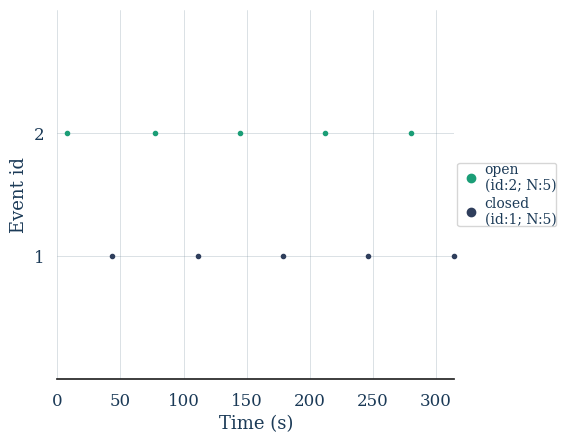

In [2]:
# Subject to analyze
i_subject = 2

# Load dataset
raw = Rodrigues2017().get_data(subjects=[i_subject])[i_subject]["0"]["0"]

# Extract events
events, event_id = mne.events_from_annotations(raw)

# Visualize event timeline
mne.viz.plot_events(events=events, event_id=event_id, sfreq=raw.info["sfreq"])

# Slice to epochs/trials
epo = mne.Epochs(raw, events, event_id, tmin=0, tmax=10, baseline=None, preload=True)

# Extract one trial for open and one for closed
open_data = epo["open"][0].get_data("Oz").flatten()
closed_data = epo["closed"][0].get_data("Oz").flatten()

Text(0.5, 1.0, 'EEG Data collected from electrode Oz')

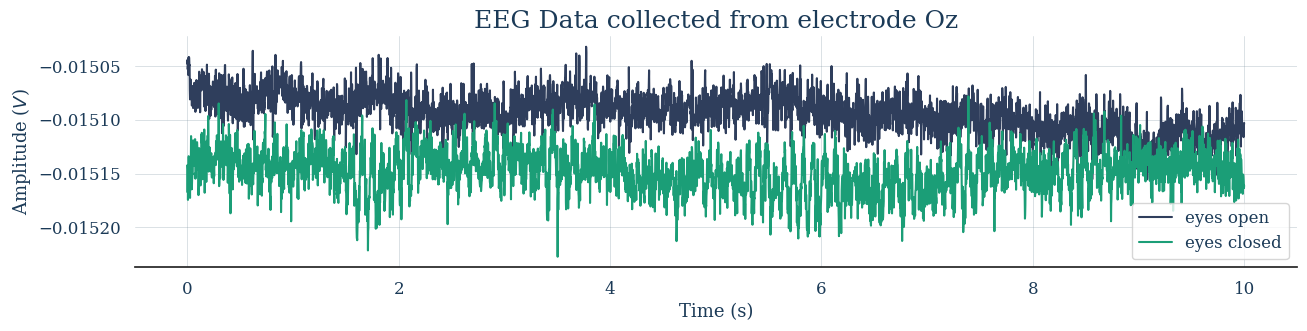

In [3]:
# Visualize data
plt.figure(figsize=(15, 3))
plt.plot(epo.times, open_data, label='eyes open')
plt.plot(epo.times, closed_data, label='eyes closed')
plt.legend()
plt.xlabel('Time (s)')
plt.ylabel('Amplitude ($V$)')
plt.title('EEG Data collected from electrode Oz')


## Exercise 2: Detrending
As you can see, the data may exhibit a (linear) trend. In such cases, it might be useful to (linearly) detrend the data. Fortunately, that is an easy thing to do, using the `detrend()` function from the `scipy.signal` library.
1. Detrend the data (a single channel and epoch is sufficient)
1. Plot the detrended data
1. What are potential causes for trends in the data? Name at least 3 possible reasons.
1. Explain in your own words what (linear) detrending does.

In [4]:
# Answer here

## Exercise 3: Spectrum
Continue with the detrended data.
1. Use the numpy or scipy functions `rfft()` and `rfftfreq()` to obtain the frequency response and frequency range of the `eyes_open` data. Plot the frequency spectrum of one channel. 
1. Observe a large peak at around 50 Hz. Can you explain what caused this peak? **Tip**: it is not because of the participant's brain. How could we remove this frequency component? **Tip**: if you can't think of a solution, finish the notebook and come back to this question later.
1. Note that we also need a sufficient number of data points to obtain a nice frequency resolution. This can be demonstrated by running the FFT on a tiny time window from our data. Do this by running the procedure from the first subexercise on a tiny portion (equal to a 16th) of the data. Compare the newly obtained spectrum to the original one. You should be able to see spectral leakage happening in the frequency spectrum obtained from fewer samples (e.g., easily apparent at the 50 Hz peak). **Tip**: If you cannot see the difference immediately, try zooming in on the first 60 frequencies.


In [5]:
# Answer here

## Exercise 4: Eyes open versus eyes closed
We have provided you with 2 recordings: One where the participant had their eyes open (`eyes_open`) and one where their eyes were closed (`eyes_closed`). 

1. What difference do you expect to see in the spectral content of the 2 recordings? At which channel do you expect that difference?
2. Plot the frequency spectrum of a single channel for each of the two conditions. Is the answer you gave to the previous question in line with what you see? **Tip:** Carefully think about which channel to visualize!

In [6]:
# Answer here

## Exercise 5: Spectrogram
The frequency spectrum we plotted shows how much each frequency contributes to the entirety of the signal. However, it is not the case that at each **time point** their contribution was equal. Instead, to capture spectro-temporal characteristics, we may want to compute the spectrogram. A spectrogram is a time-frequency representation (TFR) that, as the name suggests, gives us information about the frequency spectrum at different time points.

1. Use the `spectrogram()` function from `scipy.signal` to compute the spectrogram of the whole signal. Do this for the eyes-closed condition. Plot the spectrogram. 
2. What do you observe?

In [7]:
# Answer here

# Exercise 6: Spectral filtering

Below, we have provided an example where we create synthetic data from sinusoids with frequencies from 5 to 100 Hz, after which we filter out the ones above 16 Hz. 
1. Do the same for the EEG signal (e.g., open condition). Note that such filtering will also take out the 50 Hz powerline noise. Experiment with different filter orders and stopband/passband sizes. **Tip:** Plot the frequency spectrum before and after applying the spectral filter.

In [8]:
def generate_data_1(duration=1.0, fs=200, seed=42):
    rng = np.random.default_rng(seed)
    N = int(fs * duration)
    t = np.arange(N) / fs
    y = np.zeros(N)
    for f in range(5, 100):
        if f == 50:
            a = 3
        else:
            a = rng.random()
        y += a * np.sin(2 * np.pi * f * t + rng.random() * 2 * np.pi)
    return t, y

duration = 1.0
fs = 200
t, y = generate_data_1(duration, fs)
N = t.size

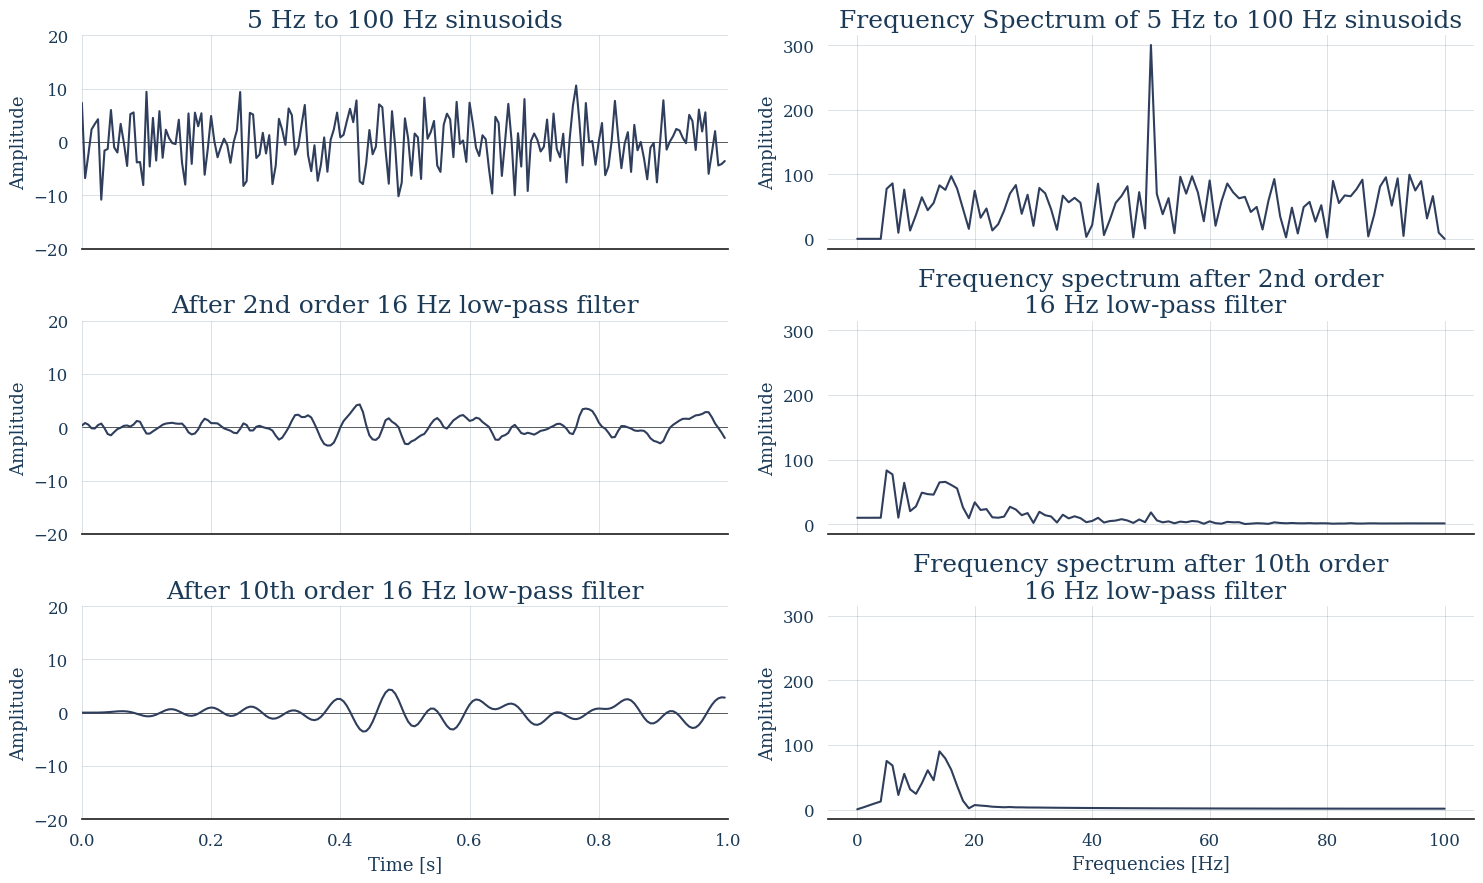

In [9]:
fig, ax = plt.subplots(3, 2, figsize=(15, 9), sharex="col", sharey="col")

ax[0][0].plot(t, y)
ax[0][0].axis([0, 1, -20, 20])
ax[0][0].axhline(0, 0,1, c='k', linewidth=0.5, zorder=0)
ax[0][0].set_title('5 Hz to 100 Hz sinusoids')
ax[0][0].set_ylabel('Amplitude')

ax[0][1].plot(fft.rfftfreq(N, 1/fs), abs(fft.rfft(y)))
ax[0][1].set_title('Frequency Spectrum of 5 Hz to 100 Hz sinusoids')
ax[0][1].set_ylabel('Amplitude')

# Apply Butterworth Low-pass Filter of 2nd order
sos2 = butter(2, 16, 'lp', fs=fs, output='sos')
filtered2 = sosfilt(sos2, y)

ax[1][0].plot(t, filtered2)
ax[1][0].axhline(0, 0,1, c='k', linewidth=0.5, zorder=0)
ax[1][0].axis([0, 1, -20, 20])
ax[1][0].set_title('After 2nd order 16 Hz low-pass filter')
ax[1][0].set_ylabel('Amplitude')

ax[1][1].plot(fft.rfftfreq(N, 1/fs), abs(fft.rfft(filtered2)))
ax[1][1].set_title('Frequency spectrum after 2nd order\n 16 Hz low-pass filter')
ax[1][1].set_ylabel('Amplitude')

# Apply Butterworth Low-pass Filter of 10th order
sos10 = butter(10, 16, 'lp', fs=fs, output='sos')
filtered10 = sosfilt(sos10, y)

ax[2][0].plot(t, filtered10)
ax[2][0].axhline(0, 0,1, c='k', linewidth=0.5, zorder=0)
ax[2][0].axis([0, 1, -20, 20])
ax[2][0].set_title('After 10th order 16 Hz low-pass filter')
ax[2][0].set_xlabel('Time [s]')
ax[2][0].set_ylabel('Amplitude')

ax[2][1].plot(fft.rfftfreq(N, 1/fs), abs(fft.rfft(filtered10)))
ax[2][1].set_title('Frequency spectrum after 10th order\n 16 Hz low-pass filter')
ax[2][1].set_xlabel('Frequencies [Hz]')
ax[2][1].set_ylabel('Amplitude')

fig.tight_layout()


In [10]:
# Answer here

## Exercise 7: Envelope
The envelope of a signal can be computed in various ways.
1. Use the square of a signal to calculate the envelope of the toy signal below and plot the signal together with its envelope.
1. Use the `hilbert()` function from `scipy.signal` to calculate the envelope of the toy signal below and plot the signal together with its envelope.
1. What differences do you observe between the two envelopes? Why would one still use the square rather than Hilbert?

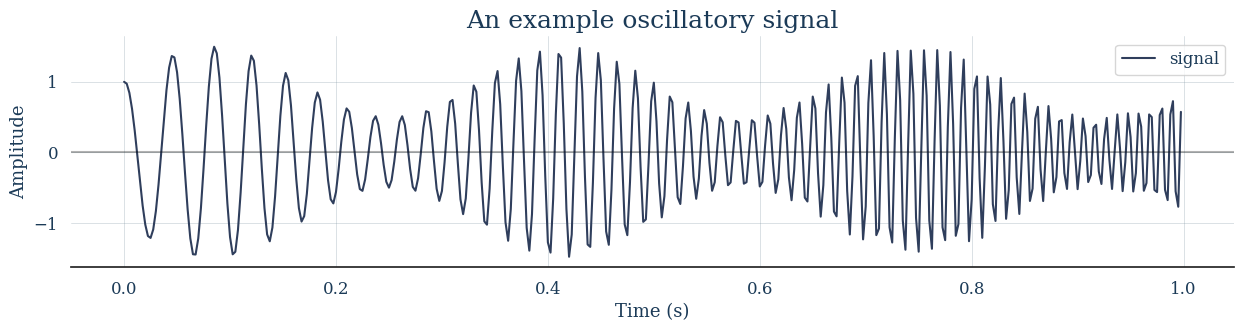

In [11]:
def generate_data_2(duration=1.0, fs=400):
    N = int(fs * duration)
    t = np.arange(N) / fs
    y = chirp(t, 20.0, t[-1], 100.0) 
    y *= (1.0 + 0.5 * np.sin(2.0 * np.pi * 3.0 * t) ) 
    return t, y

t, y = generate_data_2()

plt.figure(figsize=(15, 3))
plt.plot(t, y, label="signal")
plt.axhline(0, c='k', alpha=0.3)
plt.ylabel('Amplitude')
plt.xlabel('Time (s)')
plt.title('An example oscillatory signal')
plt.legend()

In [12]:
# Answer here